# LinearRegression
- **Linear Regression:** Linear regression is a straightforward method to model the relationship between a dependent variable and one or more independent variables by fitting a linear equation to the observed data.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.datasets import fetch_openml
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Load the Diamonds dataset
df = sns.load_dataset("diamonds")

In [ ]:
# Checking the data
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [ ]:
# separting the features and target
X = df.drop("price",axis=1)
y = df[["price"]]

In [ ]:
# features
X

,carat,cut,color,clarity,depth,table,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,6.15,6.12,3.74


In [ ]:
# getting dummies and dropping first
X_dummy = pd.get_dummies(X,drop_first=True)

In [ ]:
# data after getting dumy variables
X_dummy

,carat,depth,table,x,y,z,cut_Premium,cut_Very Good,cut_Good,cut_Fair,...,color_H,color_I,color_J,clarity_VVS1,clarity_VVS2,clarity_VS1,clarity_VS2,clarity_SI1,clarity_SI2,clarity_I1
0,0.23,61.5,55.0,3.95,3.98,2.43,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0.21,59.8,61.0,3.89,3.84,2.31,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0.23,56.9,65.0,4.05,4.07,2.31,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,0.29,62.4,58.0,4.20,4.23,2.63,1,0,0,0,...,0,1,0,0,0,0,1,0,0,0
4,0.31,63.3,58.0,4.34,4.35,2.75,0,0,1,0,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53935,0.72,60.8,57.0,5.75,5.76,3.50,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
53936,0.72,63.1,55.0,5.69,5.75,3.61,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
53937,0.70,62.8,60.0,5.66,5.68,3.56,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
53938,0.86,61.0,58.0,6.15,6.12,3.74,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0


In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_dummy, y, test_size=0.2, random_state=42)

In [ ]:
# Initialize and train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# prediction on training and testing
y_pred_test = linear_model.predict(X_test)

y_pred_train = linear_model.predict(X_train)


# Calculate metrics
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)
mae_tes = mean_absolute_error(y_test, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)
mae_train = mean_absolute_error(y_train, y_pred_train)


print("Linear Regression Results:")
print("RMSE training:", rmse_train)
print("RMSE training:", rmse_test)

#print("R-squared:", r2)
#print("MAE:", mae)

Linear Regression Results:
RMSE training: 1128.5697163572002
RMSE training: 1135.2116445190627


In [ ]:
print("R2 score training:", r2_train)
print("R2 testing:", r2_test)

R2 score training: 0.919994314909212
R2 testing: 0.9189331350419387


In [ ]:
# Initialize and train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict on the test set
y_pred = linear_model.predict(X_test)


# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Linear Regression Results:")
print("RMSE:", rmse)
print("R-squared:", r2)
print("MAE:", mae)


Linear Regression Results:
RMSE: 1135.2116445190627
R-squared: 0.9189331350419387
MAE: 737.1513665933273


- RMSE 1135 tells us that on an average our prediction will be off by 1135
- R2 score or coefficient of determination, it is a value ranging from 0-1, it tells you how much variance in the target variable is explained by the features. In our case we have r2 score of 0.91 which is extremely good.
- MAE tells us the deviation between the actual and predicted value, in our case we have a mae of 737 which says that the deviation between actual and predicted value is 737

In [ ]:
linear_model.intercept_

array([5845.41976163])

In [ ]:
linear_model.coef_.ravel()

array([ 1.12807843e+04, -6.50910151e+01, -2.66000210e+01, -1.00804160e+03,
       -3.52845036e+00, -3.64633703e+01,  2.62317252e+02,  1.85429483e+02,
        1.53453486e+02, -4.70152565e+00, -5.96498695e+02,  8.34883892e+02,
        6.16685289e+02,  5.55167489e+02,  3.39302365e+02, -1.64202516e+02,
       -6.44700578e+02, -1.53713594e+03,  1.54596651e+03,  1.19531483e+03,
        1.13823337e+03,  7.59927458e+02,  4.43637553e+02, -1.44563530e+02,
       -1.11853811e+03, -3.81997808e+03])

In [ ]:
list_ = ["red","green","blue"]
df2 = pd.DataFrame({"colors":list_})

In [ ]:
df2

,colors
0,red
1,green
2,blue


In [ ]:
pd.get_dummies(df2)

,colors_blue,colors_green,colors_red
0,0,0,1
1,0,1,0
2,1,0,0


In [ ]:
pd.get_dummies(df2,drop_first=True)

,colors_green,colors_red
0,0,1
1,1,0
2,0,0


In [ ]:
df["cut"].unique()

['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, object): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [ ]:
ideal, premium or good.


In [ ]:
coef_df = pd.DataFrame({"Name of features":X_dummy.columns,"Slope of features":linear_model.coef_.ravel()})
coef_df

,Name of features,Slope of features
0,carat,11280.784327
1,depth,-65.091015
2,table,-26.600021
3,x,-1008.041596
4,y,-3.528450
5,z,-36.463370
6,cut_Premium,-76.887768
7,cut_Very Good,-108.863766
8,cut_Good,-267.018777
9,cut_Fair,-858.815946


- We dropped the ideal dummy column, because when all other 4 categories are 0 than the cut will be for sure ideal, so we will have a regression equation for ideal cut. The premium coefficient value tells us if the cut is premium than the price will reduce by 75$ as compare to ideal.

# Ridge Regression
Ridge Regression: Ridge regression adds a penalty term (L2 regularization) to the linear regression cost function. It helps prevent overfitting by forcing the coefficients to be small.

In [ ]:
from sklearn import datasets

In [ ]:
# Initialize and train the Linear Regression model
linear_model = Ridge(alpha=1)
linear_model.fit(X_train, y_train)

# prediction on training and testing
y_pred_test = linear_model.predict(X_test)

y_pred_train = linear_model.predict(X_train)


# Calculate metrics
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)
mae_tes = mean_absolute_error(y_test, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)
mae_train = mean_absolute_error(y_train, y_pred_train)


print("Linear Regression Results:")
print("RMSE training:", rmse_train)
print("RMSE testing:", rmse_test)

#print("R-squared:", r2)
#print("MAE:", mae)

Linear Regression Results:
RMSE training: 1128.574812161737
RMSE testing: 1135.1563247270726


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.datasets import fetch_openml

# Load the Diamonds dataset
diamonds = fetch_openml(name='diamonds', version=1, as_frame=True)
data = diamonds.frame

# Preprocess the data
data = data.drop(['cut', 'color', 'clarity'], axis=1)  # Drop categorical features
data = data.dropna()  # Drop missing values

# Split the data into features (X) and target (y)
X = data.drop('price', axis=1)
y = data['price']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Ridge Regression model
ridge_model = Ridge(alpha=1.0)  # You can adjust the alpha value
ridge_model.fit(X_train, y_train)

# Predict on the test set
y_pred = ridge_model.predict(X_test)

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Ridge Regression Results:")
print("RMSE:", rmse)
print("R-squared:", r2)
print("MAE:", mae)


# Lasso Regression
-Lasso Regression: Lasso regression also adds a penalty term (L1 regularization) to the linear regression cost function. It not only prevents overfitting but also tends to force some coefficients to be exactly zero, effectively performing feature selection.

# Elastic Regression
- Elastic Net Regression: Elastic Net is a combination of Ridge and Lasso regression. It adds both L1 and L2 regularization terms to the cost function. This provides a balance between the two regularization methods.

In [ ]:
X_dummy.head()

,carat,depth,table,x,y,z,cut_Premium,cut_Very Good,cut_Good,cut_Fair,...,color_H,color_I,color_J,clarity_VVS1,clarity_VVS2,clarity_VS1,clarity_VS2,clarity_SI1,clarity_SI2,clarity_I1
0,0.23,61.5,55.0,3.95,3.98,2.43,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0.21,59.8,61.0,3.89,3.84,2.31,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0.23,56.9,65.0,4.05,4.07,2.31,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,0.29,62.4,58.0,4.20,4.23,2.63,1,0,0,0,...,0,1,0,0,0,0,1,0,0,0
4,0.31,63.3,58.0,4.34,4.35,2.75,0,0,1,0,...,0,0,1,0,0,0,0,0,1,0


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
X_scaled = StandardScaler().fit_transform(X_dummy)

In [ ]:
X_scaled.shape

(53940, 23)

In [ ]:
y.shape

(100,)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
lr = LinearRegression()
ridge = Ridge(alpha=0.1)
lasso = Lasso(alpha=0.1)
elastic_net = ElasticNet(alpha=0.1)

rmse = []
model_names = ["Linear Regression","Ridge","Lasso","Elastic Net"]
models = [lr,ridge,lasso,elastic_net]
for model, name in zip(models,model_names):
  model.fit(X_train,y_train)
  y_pred_train = model.predict(X_train)
  y_pred_test = model.predict(X_test)
  rmse_test = np.sqrt(mean_squared_error(y_test,y_pred_test))
  rmse.append(rmse_test)
  print(name)
  print("RMSE training",np.sqrt(mean_squared_error(y_train,y_pred_train)))
  print("RMSE testing",np.sqrt(mean_squared_error(y_test,y_pred_test)))

Linear Regression
RMSE training 1128.5697163572002
RMSE testing 1135.2116445190625
Ridge
RMSE training 1128.5697187076705
RMSE testing 1135.2107295345938
Lasso
RMSE training 1128.5710423568453
RMSE testing 1135.1717228010257
Elastic Net
RMSE training 1263.2138213072883
RMSE testing 1254.1818062880866


Text(0.5, 1.0, 'Comparison of models (RMSE)')

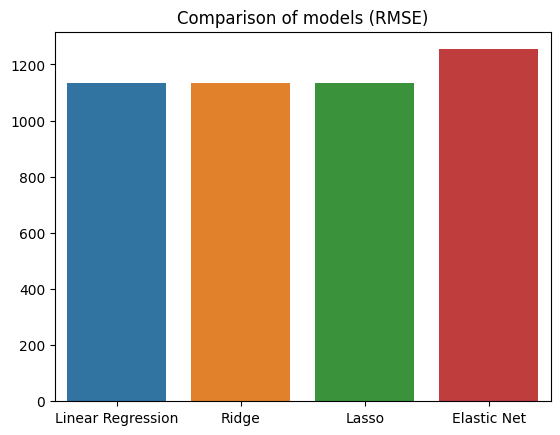

In [ ]:
sns.barplot(x = model_names,y=rmse)
plt.title("Comparison of models (RMSE)")

In [ ]:
import seaborn as sns

In [ ]:
df = sns.load_dataset("brain_networks")

In [ ]:
df.head()

,network,1,1.1,2,2.1,3,3.1,4,4.1,5,...,16.5,16.6,16.7,17,17.1,17.2,17.3,17.4,17.5,17.6
0,node,1,1,1,1,1,1,1,1,1,...,3,4,4,1,1,2,2,3,3,4
1,hemi,lh,rh,lh,rh,lh,rh,lh,rh,lh,...,rh,lh,rh,lh,rh,lh,rh,lh,rh,lh
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,56.05574417114258,92.03103637695312,3.391575574874878,38.65968322753906,26.203819274902344,-49.71556854248047,47.4610366821289,26.746612548828125,-35.898860931396484,...,0.6079040169715881,-70.27054595947266,77.36577606201172,-21.73455047607422,1.0282527208328247,7.7917842864990225,68.90372467041016,-10.520872116088867,120.49046325683594,-39.686431884765625
4,1,55.5472526550293,43.6900749206543,-65.49598693847656,-13.974522590637207,-28.27496337890625,-39.05012893676758,-1.2106596231460571,-19.012897491455078,19.568010330200195,...,57.49507141113281,-76.39321899414062,127.26136016845705,-13.035799026489258,46.3818244934082,-15.752449989318848,31.00033187866211,-39.607521057128906,24.76401138305664,-36.7710075378418


In [ ]:
df.shape

(923, 63)